In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- same dividing-line definition as before ----
FE_BREAK = -0.1
M1, B1 = -0.05, 0.10
M2 = -0.20
B2 = (M1 * FE_BREAK + B1) - M2 * FE_BREAK

FEH_CUT = -1.2
feh_min_extra = -0.9

def alpha_dividing_line(feh_vals, fe_break=FE_BREAK, m1=M1, b1=B1, m2=M2, b2=B2):
    feh_vals = np.asarray(feh_vals, float)
    return np.where(feh_vals >= fe_break, m1 * feh_vals + b1, m2 * feh_vals + b2)

# ---- load the FULL (uncut) sim, so we can see the whole chemical distribution ----
merger_all = pd.read_parquet("merger_sim_disc_all.parquet")

feh = merger_all["feh"].to_numpy()
ofe = merger_all["ofe"].to_numpy()
is_thin = merger_all["is_thin_disc"].to_numpy()
is_new_mw = merger_all["is_new_mw"].to_numpy()
tag_sel = is_thin | is_new_mw   # the tag-based selection that worked

finite = np.isfinite(feh) & np.isfinite(ofe)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)

feh_grid = np.linspace(np.nanpercentile(feh[finite], 0.5), np.nanpercentile(feh[finite], 99.5), 200)
div_line = alpha_dividing_line(feh_grid)

# --- left panel: full population density, with the cut line overlaid ---
ax = axes[0]
h = ax.hexbin(feh[finite], ofe[finite], gridsize=120, cmap="Greys", bins="log", mincnt=1)
ax.plot(feh_grid, div_line, color="crimson", lw=2, label="low-$\\alpha$ dividing line (real-data cut)")
ax.axvline(FEH_CUT, color="orange", ls="--", lw=1.5, label=f"[Fe/H] = {FEH_CUT} (FEH_CUT)")
ax.axvline(feh_min_extra, color="goldenrod", ls="--", lw=1.5, label=f"[Fe/H] = {feh_min_extra} (extra floor)")
ax.set_xlabel("[Fe/H] (sim)")
ax.set_ylabel("[O/Fe] (sim)")
ax.set_title("All MW-tagged sim stars")
ax.legend(fontsize=8, loc="upper right")
fig.colorbar(h, ax=ax, label="log$_{10}$(N)")

# --- right panel: same, but highlighting where the tag-based ("working") selection sits ---
ax = axes[1]
h2 = ax.hexbin(feh[finite & tag_sel], ofe[finite & tag_sel], gridsize=120, cmap="Blues", bins="log", mincnt=1)
#ax.set_xlabel("[Fe/H] (sim)")
ax.set_ylabel("[O/Fe] (sim)")
ax.set_title("is_thin_disc | is_new_mw tagged stars\n(the selection that recovered z0 cleanly)")
ax.legend(fontsize=8, loc="upper right")
fig.colorbar(h2, ax=ax, label="log$_{10}$(N)")

plt.tight_layout()
plt.show()

# --- quantify: what fraction of the tag-based ("good") sample actually passes the chemistry cut? ---
chem_mask = finite & (ofe < alpha_dividing_line(feh)) & (feh >= FEH_CUT) & (feh > feh_min_extra) & (merger_all["R"].to_numpy() < 16.0)

n_tag = int((finite & tag_sel).sum())
n_tag_and_chem = int((finite & tag_sel & chem_mask).sum())
n_chem = int(chem_mask.sum())
n_chem_and_tag = int((chem_mask & tag_sel).sum())

print(f"tag-based sample (is_thin_disc | is_new_mw): {n_tag:,} stars")
print(f"  of those, {n_tag_and_chem:,} ({100*n_tag_and_chem/n_tag:.1f}%) also pass the chemistry cut")
print(f"chemistry-cut sample: {n_chem:,} stars")
print(f"  of those, {n_chem_and_tag:,} ({100*n_chem_and_tag/n_chem:.1f}%) are also tag-based thin_disc/new_mw")

## Original method

In [7]:
import numpy as np
import pandas as pd

RMAX_KEEP = 16.0   # same R cut as before (matches rmax_keep in your real pipeline)

def apply_tag_cuts(df):
    R = df["R"].to_numpy()
    tag_sel = df["is_thin_disc"].to_numpy() | df["is_new_mw"].to_numpy()

    finite_mask = (np.isfinite(df["R"]) & np.isfinite(df["z"])
                   & np.isfinite(df["phi"]) & np.isfinite(df["ofe"]))
    R_mask = R < RMAX_KEEP

    keep = finite_mask & tag_sel & R_mask
    out = df[keep].reset_index(drop=True)

    print(f"  input: {len(df):,}")
    print(f"  after is_thin_disc | is_new_mw: {(finite_mask & tag_sel).sum():,}")
    print(f"  after R < {RMAX_KEEP} kpc cut: {keep.sum():,}")
    return out

merger_all = pd.read_parquet("merger_sim_disc_all.parquet")
host_all   = pd.read_parquet("host_sim_disc_all.parquet")

print("merger sim:")
merger_cut = apply_tag_cuts(merger_all)
print("\nhost-only sim:")
host_cut = apply_tag_cuts(host_all)

merger_cut.to_parquet("merger_sim_disc_cut.parquet", compression="zstd", index=False)
host_cut.to_parquet("host_sim_disc_cut.parquet", compression="zstd", index=False)

merger sim:
  input: 3,000,000
  after is_thin_disc | is_new_mw: 2,496,669
  after R < 16.0 kpc cut: 2,365,572

host-only sim:
  input: 3,000,000
  after is_thin_disc | is_new_mw: 2,625,559
  after R < 16.0 kpc cut: 2,457,016


In [9]:
import os
import pickle
import numpy as np
from itertools import product

def fit_z0_grid_sech2(df, R_edges, segm, seg_ids, alpha_col="ofe", results_path=None, force_rerun=False):
    if results_path and os.path.exists(results_path) and not force_rerun:
        with open(results_path, "rb") as f:
            saved = pickle.load(f)
        if "per_cell" in saved:
            return saved["z0_med"], saved["z0_std"], saved["ok_grid"], saved["per_cell"]
        else:
            print("cached file has no per_cell data -- rerun with force_rerun=True to get it")
            return saved["z0_med"], saved["z0_std"], saved["ok_grid"], {}

    R_arr = df["R"].to_numpy()
    Z_arr = df["z"].to_numpy()
    mgfe_arr = df[alpha_col].to_numpy()
    err_arr = np.ones_like(mgfe_arr)

    n_R, n_seg = len(R_edges) - 1, len(seg_ids)
    z0_med  = np.full((n_R, n_seg), np.nan)
    z0_std  = np.full((n_R, n_seg), np.nan)
    ok_grid = np.zeros((n_R, n_seg), dtype=bool)
    per_cell = {}

    key = jr.PRNGKey(0)
    pairs = list(product(range(n_R), range(n_seg)))

    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = seg_ids[j_seg]
        z_binc_k, mean_k, err_k, ns_k, ok_k = select_annulus_segment_sim(
            R_arr, Z_arr, mgfe_arr, err_arr, seg_mask=segm[seg_id], Rmin=Rmin, Rmax=Rmax)
        if not ok_k:
            continue
        try:
            key, sub = jr.split(key)
            sampler_k = fit_sech2(z_binc_k, mean_k, err_k, sub, progress_bar=False)
            samples_k = sampler_k.get_samples()
            z0_med[i_R, j_seg] = float(np.median(samples_k["z0"]))
            z0_std[i_R, j_seg] = float(np.std(samples_k["z0"]))
            ok_grid[i_R, j_seg] = True
            per_cell[(i_R, j_seg)] = {
                "Rmin": Rmin, "Rmax": Rmax, "seg_id": seg_id,
                "z_binc": z_binc_k, "mean": mean_k, "err": err_k,
                "samples": {kk: np.asarray(vv[:1000]) for kk, vv in samples_k.items()},
            }
        except Exception as e:
            print(f"  fit failed: seg={seg_id} R=[{Rmin:.1f},{Rmax:.1f}] -> {e}")
        if k % 20 == 0 or k == len(pairs):
            print(f"  done {k}/{len(pairs)}", flush=True)

    if results_path:
        with open(results_path, "wb") as f:
            pickle.dump({"z0_med": z0_med, "z0_std": z0_std, "ok_grid": ok_grid,
                         "per_cell": per_cell}, f)

    return z0_med, z0_std, ok_grid, per_cell

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6156/732998973.py:54: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6156/732998973.py:55: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6156/732998973.py:62: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 20/330
  done 40/330
  done 60/330
  done 80/330
  done 100/330
  done 120/330
  done 140/330
  done 160/330
  done 180/330
  done 200/330
  done 220/330
  done 240/330
  done 260/330
  done 280/330
  done 300/330
  done 320/330
  done 330/330
Merger sim: 330/330 cells fit successfully


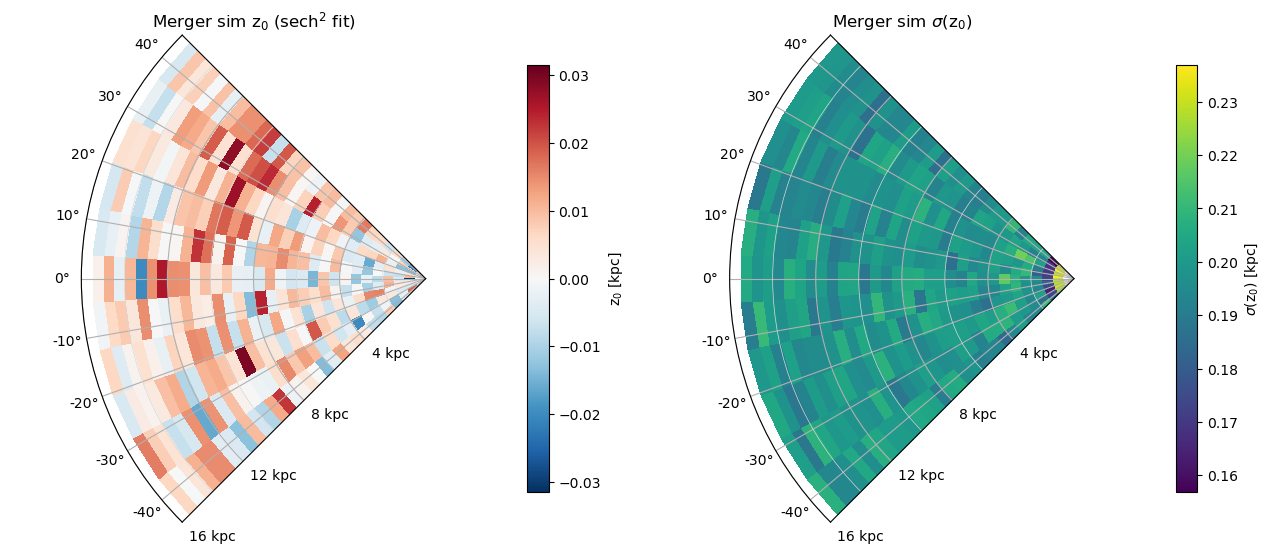

/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6156/732998973.py:54: RuntimeWarning: invalid value encountered in divide
  mean_mg_fe = stat1.statistic / stat2.statistic
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6156/732998973.py:55: RuntimeWarning: divide by zero encountered in divide
  mean_mg_fe_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter**2)
/var/folders/6v/s_h7sm_95_j5djq7d1sz66vr0000gn/T/ipykernel_6156/732998973.py:62: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


  done 20/330
  done 40/330
  done 60/330


KeyboardInterrupt: 

In [10]:
import pandas as pd
from src.coords import build_segment_setup

merger_cut = pd.read_parquet("merger_sim_disc_cut.parquet")
host_cut   = pd.read_parquet("host_sim_disc_cut.parquet")

for name, df, results_path in [
    ("Merger sim", merger_cut, "sech2_mcmc_results_merger_sim_tagcut.pkl"),
    ("Host-only sim", host_cut, "sech2_mcmc_results_host_sim_tagcut.pkl"),
]:
    segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
        df["phi"].to_numpy(), phi0=np.pi, crowd_halfwidth_deg=45, n_crowd=11
    )
    seg_ids = list(range(1, seg_diag["n_crowd"] + 1))

    z0_med, z0_std, ok_grid, per_cell = fit_z0_grid_sech2(
        df, R_edges, segm, seg_ids, alpha_col="ofe",
        results_path=results_path, force_rerun=True
    )
    print(f"{name}: {ok_grid.sum()}/{ok_grid.size} cells fit successfully")

    plot_z0_heatmap_sim(z0_med, z0_std, crowd_bounds, title_prefix=name)